# Final Delta production: GEVP 2pt → gluon 3pt (method 1) → ratio → fits

Input: the packed final 2pt (`delta_package_final.py`, 3072 sources per cfg, stream e) and the local HYP FF file (stream e, q = 0, HYP 0-8, w 0-9).

1. **GEVP**: per half (forward, backward) the GEVP of the source-averaged operator matrix; the 2pt of every cfg and t_src is reconstructed with the ground-state vector $v_0$ at `t_ref` and saved with the GEVP parameters.
2. **3pt, method 1**: connected $\langle C_2\,O\rangle$ minus $\langle C_2\rangle\langle O\rangle$ per jackknife replicate, forward and backward, saved.
3. **Ratio**: $R = \mathrm{Re}\,C_3 / \mathrm{Re}\,C_2$ for forward, backward and their average (fb), saved with plots.
4. **Fits**: the 2pt fit for the gap priors (same model as `2PT_simple/2pt_fit_packagecode.py`) and the ratio fit (same model as `fit_ratio_hyp.py`).

Everything is written to `out_dir`. Each section reads what the one before saved, so after the settings cell any section can be rerun alone.

In [17]:
#======== settings, used by every section ========
import os
import re
import json
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt
from opt_einsum import contract

here = "/Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta"
pack_dir = here                                             # packed 2pt files (delta_package_final.py)
out_dir = f"{here}/final_production"                        # everything this notebook writes
FF_path = "/Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/FF_symmetric_q0_0_0_hyp0-1-2-3-4-5-6-7-8_fb_tins18_ncfg799.h5"

hadron = "pion"                                             # "pion" or "proton"

#GEVP basis (section 1): smear 0 = [4.5, 2.25, 0.8], 1 = [1.5, 1.5, 0];  gamma 0 = G5, 1 = G5G4, 2 = G3G5
smear_use = [0, 1]
gamma_use = [0,1,2]
t0 = 2                                                      # GEVP reference time
t_ref = 4                                                   # time of the ground-state vector v0 that reconstructs the 2pt
c_sign = {"pion": -1, "proton": +1}[hadron]                 # the pion comes out negative (the fermion-loop sign is not in the code), the projected proton positive
m_had = {"pion": 0.141, "proton": 0.51}[hadron]             # dispersion line only; proton: 6x6 GEVP at pz = 0, t = 8..11 (look_packed_final.py)

operator = "TXTXpTYTYm2XYXY"                                # the operator of the ratio and the fits (sections 3, 4)
Ls, Lt = 32, 96
op_names = ["TXTX", "TYTY", "XYXY", "TXTXpTYTY", "TXTXpTYTYm2XYXY", "TXTXpTYTYp2XYXY"]


def jk(data, jk_axis=0):
    n = data.shape[jk_axis]
    data = np.moveaxis(data, jk_axis, 0)
    mean = np.mean(data, axis=0)
    err = np.sqrt((n - 1.0) / n * np.sum((data - mean) ** 2, axis=0))
    return mean, err


def jackknife(x):
    n_cfg = x.shape[0]
    return (x.sum(axis=0) - x) / (n_cfg - 1)


def text(values):
    return [v.decode() if isinstance(v, bytes) else str(v) for v in values]


#file names shared by the sections
pack_file = max(glob.glob(f"{pack_dir}/2pt_*_{hadron}.h5"), key=lambda name: int(name.split("_ncfg")[1].split("_")[0]))   # the pack with the most cfgs
with h5py.File(pack_file, "r") as f:
    n_cfg = len(f["cfg_list"])
n_src = int(re.search(r"_(\d+)src_", pack_file).group(1))
with h5py.File(FF_path, "r") as f:
    hyp_tag = f"{f['hyp_list'][0]}-{f['hyp_list'][-1]}"
basis_tag = "smear" + "".join(str(s) for s in smear_use) + "_gamma" + "".join(str(g) for g in gamma_use)
pt2_tag = f"{basis_tag}_t0{t0}_tref{t_ref}"
run_tag = f"{n_src}src_ncfg{n_cfg}"
q_tag = "q000"
rec_path = f"{out_dir}/2pt_reconstructed_{hadron}_{pt2_tag}_{run_tag}.h5"
pt3_path = {d: f"{out_dir}/pt3_jk_method1_{hadron}_gevp_{pt2_tag}_{d}_{q_tag}_hyp{hyp_tag}_{run_tag}.h5" for d in ("forward", "backward")}
ratio_dir = f"{out_dir}/ratio_data"
plot_dir = f"{out_dir}/plots"
def ratio_path(d):
    return f"{ratio_dir}/ratio_method1_{hadron}_gevp_{pt2_tag}_{d}_{operator}_{q_tag}_hyp{hyp_tag}_{run_tag}.h5"
for folder in [out_dir, ratio_dir, plot_dir]:
    os.makedirs(folder, exist_ok=True)
print(f"{hadron}: {os.path.basename(pack_file)}  ({n_cfg} cfgs)")
print(f"GEVP basis {basis_tag}, t0 = {t0}, t_ref = {t_ref};  output in {out_dir}")

pion: 2pt_coulomb_rho4p5z2p25-rho1p5_frac0p8-0_paired_GEVP_q000_asy_fb_tsep20_3072src_ncfg62_pion.h5  (62 cfgs)
GEVP basis smear01_gamma012, t0 = 2, t_ref = 4;  output in /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production


## 1. GEVP: reconstructed 2pt

Per half the source-averaged matrix $C(t)$ of the basis (hermitian part, sign `c_sign`); GEVP $C(t)v = \lambda C(t_0) v$ on its mean; $v_0$ = ground-state vector at `t_ref`, normalized to $v_0^\dagger C(t_0) v_0 = 1$. The 2pt of every cfg and t_src is `c_sign` $v_0^\dagger C v_0$ with that half's $v_0$ (the same $v_0$ for every cfg). The proton is projected to positive parity first: forward $\mathrm{tr}[P_+ M]$, backward $-\mathrm{tr}[P_- M]$.

pt2 shape (cfg, smear_snk, smear_src, g_snk, g_src, t_src, q, pz, tsep): (62, 2, 2, 3, 3, 24, 1, 7, 20)
basis 6x6: ['rho4p5z2p25 G5', 'rho4p5z2p25 G5G4', 'rho4p5z2p25 G3G5', 'rho1p5 G5', 'rho1p5 G5G4', 'rho1p5 G3G5'] (checked against the pack)
forward: max over pz of |<C_rec(t0)> - 1| = 4.3e-15
backward: max over pz of |<C_rec(t0)> - 1| = 1.1e-15
pz 0: reconstructed meff t = 4..10  0.1433(0.0005) 0.1418(0.0005) 0.1412(0.0006) 0.1417(0.0005) 0.1413(0.0006) 0.1409(0.0005) 0.1409(0.0006)
pz 1: reconstructed meff t = 4..10  0.2480(0.0005) 0.2446(0.0006) 0.2440(0.0006) 0.2438(0.0007) 0.2441(0.0008) 0.2431(0.0009) 0.2433(0.0008)
pz 2: reconstructed meff t = 4..10  0.4336(0.0008) 0.4273(0.0010) 0.4237(0.0013) 0.4222(0.0018) 0.4245(0.0024) 0.4196(0.0029) 0.4139(0.0036)
pz 3: reconstructed meff t = 4..10  0.6322(0.0010) 0.6223(0.0015) 0.6132(0.0023) 0.6108(0.0043) 0.6121(0.0051) 0.6004(0.0086) 0.5690(0.0144)
pz 4: reconstructed meff t = 4..10  0.8232(0.0011) 0.8122(0.0016) 0.7999(0.0031) 0.7989

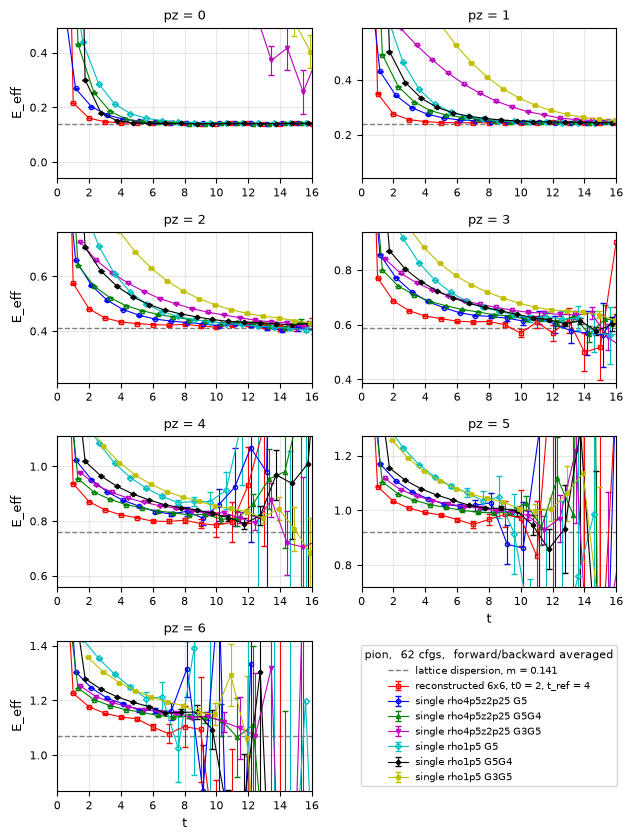

saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/2pt_reconstructed_pion_smear01_gamma012_t02_tref4_3072src_ncfg62.h5


In [18]:
#======== 1. GEVP: reconstructed 2pt per cfg and t_src ========
def solve_gevp(C_matrix):
    eigen_val = np.full((n_pf, n_op, len(t_list)), np.nan)
    eigen_vec = np.full((n_pf, n_op, len(t_list), n_op), np.nan, "<c16")
    for ipf in range(n_pf):
        L = np.linalg.cholesky(C_matrix[:, :, ipf, t0])
        L_inv = np.linalg.inv(L)
        for it, t in enumerate(t_list):
            M = L_inv @ C_matrix[:, :, ipf, t] @ L_inv.conj().T
            w, u = np.linalg.eigh(M)
            v = L_inv.conj().T @ u
            order = np.argsort(w)[::-1]
            eigen_val[ipf, :, it] = w[order]
            eigen_vec[ipf, :, it] = v[:, order].T
    return eigen_val, eigen_vec


#---- read the pack: (cfg, smear_snk, smear_src, g_snk, g_src, [dirac_snk, dirac_src,] t_src, q, pz, tsep)
with h5py.File(pack_file, "r") as f:
    cfg_list = f["cfg_list"][:]
    t_src_list = f["t_src_list"][:]                         # (cfg, t_src)
    q_list = f["q_list"][:]
    pf_list = f["pf_list"][:]                               # (q, pz, 3): p_f of every entry
    smear_list = f["smear_list"][:]
    smear_names = text(f["smear_names"][:])
    gamma_list = text(f.attrs["gamma_list"])
    pt2 = {}
    for half in ["forward", "backward"]:
        if hadron == "proton":                              # positive parity, one cfg at a time (the proton pack is several GB)
            proj = f["parity_p"][:] if half == "forward" else -f["parity_m"][:]
            pt2[half] = np.stack([np.einsum("kl,abcdlktqpT->abcdtqpT", proj, f[f"pt2_{half}"][ic]) for ic in range(n_cfg)])
        else:
            pt2[half] = f[f"pt2_{half}"][:]
print("pt2 shape (cfg, smear_snk, smear_src, g_snk, g_src, t_src, q, pz, tsep):", pt2["forward"].shape)

#---- the basis: (cfg, op_snk, op_src, t_src, q, pz, tsep), operator a = n_gamma * i_smear + i_gamma (over smear_use, gamma_use)
n_smear, n_gamma = len(smear_use), len(gamma_use)
n_op = n_smear * n_gamma
pt2_matrix = {}
for half in pt2:
    x = pt2[half][:, smear_use][:, :, smear_use][:, :, :, gamma_use][:, :, :, :, gamma_use]
    n_tsrc, n_q, n_pf, tsep_max = x.shape[5:]
    pt2_matrix[half] = x.transpose(0, 1, 3, 2, 4, 5, 6, 7, 8).reshape(n_cfg, n_op, n_op, n_tsrc, n_q, n_pf, tsep_max)
op_pairs = [(s, g) for s in smear_use for g in gamma_use]                  # same order as the operator index
for half in pt2:
    for a, (s_snk, g_snk) in enumerate(op_pairs):
        for b, (s_src, g_src) in enumerate(op_pairs):
            assert np.array_equal(pt2_matrix[half][:, a, b], pt2[half][:, s_snk, s_src, g_snk, g_src]), f"operator pair ({a}, {b}) does not match the pack"
op_labels = [f"{smear_names[s]} {gamma_list[g]}" for s, g in op_pairs]
print(f"basis {n_op}x{n_op}:", op_labels, "(checked against the pack)")

#---- GEVP on the q = 0 mean of each half
iq0 = q_list.tolist().index([0, 0, 0])
C = {}
for half in pt2_matrix:
    C_half = pt2_matrix[half][:, :, :, :, iq0].mean(axis=3)                 # (cfg, op, op, pz, tsep): mean over t_src
    C[half] = c_sign * 0.5 * (C_half + np.conj(np.swapaxes(C_half, 1, 2)))  # hermitian part
    assert (np.einsum("aapt->apt", C[half].mean(axis=0))[:, :, t0].real > 0).all(), f"{half}: diagonal of C(t0) is not positive, check c_sign for {hadron}"
t_list = np.arange(t0 + 1, tsep_max)
it_ref = list(t_list).index(t_ref)
v0 = {}
for half in C:
    eigen_val, eigen_vec = solve_gevp(C[half].mean(axis=0))
    v0[half] = eigen_vec[:, 0, it_ref, :]                                   # (pz, op)

#---- reconstructed 2pt of every cfg, t_src and q: (cfg, t_src, q, pz, tsep); for q != 0 the same v0(pz) is used
pt2_rec = {}
for half in pt2_matrix:
    pt2_rec[half] = c_sign * np.einsum("pa,cabtqpT,pb->ctqpT", np.conj(v0[half]), pt2_matrix[half], v0[half])
    deviation = np.abs(pt2_rec[half][:, :, iq0, :, t0].mean(axis=(0, 1)).real - 1).max()
    print(f"{half}: max over pz of |<C_rec(t0)> - 1| = {deviation:.1e}")
    assert deviation < 1e-10, f"{half}: v0 is not normalized to v0^dag C(t0) v0 = 1"

#---- effective mass: reconstructed 2pt and the diagonals of the basis, q = 0, mean over t_src, forward/backward averaged
rec_fb = 0.5 * (pt2_rec["forward"][:, :, iq0].mean(axis=1) + pt2_rec["backward"][:, :, iq0].mean(axis=1)).real      # (cfg, pz, tsep)
curves = [(f"reconstructed {n_op}x{n_op}, t0 = {t0}, t_ref = {t_ref}", rec_fb)]
for a in range(n_op):
    curves.append((f"single {op_labels[a]}", 0.5 * (C["forward"][:, a, a] + C["backward"][:, a, a]).real))
meff = []
with np.errstate(invalid="ignore", divide="ignore"):
    for label, c2 in curves:
        mean = np.log(c2.mean(axis=0)[:, :-1] / c2.mean(axis=0)[:, 1:])
        c2_jk = jackknife(c2)
        meff.append((label, mean, jk(np.log(c2_jk[:, :, :-1] / c2_jk[:, :, 1:]))[1]))
pz_list = pf_list[iq0][:, 2]
for ip, pz in enumerate(pz_list):
    print(f"pz {pz}: reconstructed meff t = 4..10  " + " ".join(f"{meff[0][1][ip, t]:.4f}({meff[0][2][ip, t]:.4f})" for t in range(4, 11)))

t_meff = np.arange(tsep_max - 1)
plt.figure(figsize=(6.5, 8.5))                              # one page in LaTeX: 6.5 in wide, 8.5 in tall
for ip, pz in enumerate(pz_list):
    plt.subplot(4, 2, ip + 1)                               # 2 + 2 + 2 + 1 panels, filled row by row
    p_lat = 2 * np.pi * pz / Ls
    E_disp = 2 * np.arcsinh(np.sqrt(np.sinh(m_had / 2) ** 2 + np.sin(p_lat / 2) ** 2))
    plt.axhline(E_disp, color="gray", lw=1, ls="--", label=f"lattice dispersion, m = {m_had}")
    for i, (label, mean, err) in enumerate(meff):
        plt.errorbar(t_meff + 0.15 * i, mean[ip], yerr=err[ip], fmt=["rs-", "bo-", "g^-", "mv-", "cD-", "kP-", "yX-"][i % 7],
                     capsize=2, ms=3, mfc="none", lw=0.8, label=label)
    plt.ylim(E_disp - 0.2, E_disp + (0.35 if hadron == "pion" else 0.6))
    plt.xlim(0, 16)
    plt.xticks(np.arange(0, 17, 2), fontsize=8)
    plt.yticks(fontsize=8)
    plt.grid(alpha=0.3)
    plt.title(f"pz = {pz}", fontsize=9)
    if ip >= len(pz_list) - 2:
        plt.xlabel("t", fontsize=9)
    if ip % 2 == 0:
        plt.ylabel("E_eff", fontsize=9)
    if ip == 0:
        handles, labels = plt.gca().get_legend_handles_labels()
plt.subplot(4, 2, 8)                                        # the empty 8th slot holds the legend
plt.axis("off")
plt.legend(handles, labels, loc="center", fontsize=7, title=f"{hadron},  {n_cfg} cfgs,  forward/backward averaged", title_fontsize=8)
plt.tight_layout()
plt.savefig(f"{plot_dir}/meff_reconstructed_{hadron}_{pt2_tag}_{run_tag}.pdf")
plt.show()

#---- save, with the GEVP parameters
with h5py.File(rec_path, "w") as f:
    f.create_dataset("pt2_forward", data=pt2_rec["forward"])                # (cfg, t_src, q, pz, tsep)
    f.create_dataset("pt2_backward", data=pt2_rec["backward"])
    f.create_dataset("v0_forward", data=v0["forward"])                      # (pz, op)
    f.create_dataset("v0_backward", data=v0["backward"])
    f.create_dataset("cfg_list", data=cfg_list)
    f.create_dataset("t_src_list", data=t_src_list)
    f.create_dataset("q_list", data=q_list)
    f.create_dataset("pf_list", data=pf_list)                               # (q, pz, 3)
    f.create_dataset("smear_use", data=np.array(smear_use))
    f.create_dataset("gamma_use", data=np.array(gamma_use))
    f.create_dataset("smear_list", data=smear_list[smear_use])              # rows [rho_T, rho_z, mom_frac] of the smearings used
    f.create_dataset("operator_labels", data=np.array(op_labels, dtype=h5py.string_dtype()))
    f.attrs["hadron"] = hadron
    f.attrs["dim_pt2"] = "cfg, t_src, q, pz, tsep"
    f.attrs["dim_v0"] = f"pz, op;  operator a = {n_gamma} * i_smear + i_gamma, i_smear over smear_use, i_gamma over gamma_use"
    f.attrs["t0"] = t0
    f.attrs["t_ref"] = t_ref
    f.attrs["c_sign"] = c_sign
    f.attrs["gevp"] = (f"per half: C(t) = c_sign * hermitian part of the t_src-averaged q = 0 matrix of the {n_op} operators; GEVP C(t) v = lambda C(t0) v "
                       f"on its mean over cfgs (Cholesky of C(t0)); v0 = ground-state vector at t_ref, normalized to v0^dag C(t0) v0 = 1; "
                       f"pt2 = c_sign v0^dag C v0 per cfg and t_src with that half's v0 (the same v0 for every cfg)")
    f.attrs["proton_projection"] = "forward tr[P+ M], backward -tr[P- M] before the GEVP" if hadron == "proton" else "none (pion)"
    f.attrs["note"] = "q index of [0, 0, 0] is the plain 2pt; for q != 0 the same v0(pz) is used at source and sink"
    f.attrs["source_pack"] = pack_file
print("saved", rec_path)

## 2. 3pt, method 1

The FF file holds the operator only on the old 8 source times (spacing 12, 18 τ each); those tile all 96 time slices, so $O(t)$ is rebuilt on the full time extent and read at the 24 source times of the 2pt (the rebuild is checked against every stored FF value, forward and backward). Method 1: connected $\langle C_2(t_{\rm src})\,O(t_{\rm src} \pm \tau)\rangle$ averaged over sources, minus $\langle C_2\rangle\langle O\rangle$ per jackknife replicate.

In [20]:
#======== 2. 3pt, method 1 ========
#---- reconstructed 2pt from section 1: (cfg, t_src, q, pz, tsep)
with h5py.File(rec_path, "r") as f:
    pt2_rec = {d: f[f"pt2_{d}"][:] for d in ("forward", "backward")}
    cfg_list = f["cfg_list"][:]
    t_src_list = f["t_src_list"][:]
    q_list_pt2 = f["q_list"][:].tolist()
    pf_list = f["pf_list"][:]
    pt2_note = f"GEVP {pt2_tag}: " + str(f.attrs["gevp"])
n_cfg, n_tsrc, _, n_pf, tsep_max = pt2_rec["forward"].shape

#---- the three FF components of the operators, on the cfgs of the 2pt; FF munu order [XY, YZ, XZ, XT, YT, ZT]
with h5py.File(FF_path, "r") as f:
    FF_cfg_list = f["cfg_list"][:].tolist()
    hyp_list = f["hyp_list"][:]
    w_list = f["w_list"][:]
    q_list = f["q_list"][:]
    FF_smearing = str(f.attrs["smearing"])
    assert q_list.tolist() == [[0, 0, 0]], "q = 0 FF only: a q != 0 FF also needs the Wilson-line centering phase exp(-i pi q_z w / Ls)"
    idx = [FF_cfg_list.index(int(c)) for c in cfg_list]                    # increasing, as h5py needs
    FF = {(name, d): f[f"FF_{d}"][idx, :, mu, mu] for name, mu in [("TXTX", 3), ("TYTY", 4), ("XYXY", 0)] for d in ("forward", "backward")}   # (cfg, s, hyp, w, q, tau)
iq = [q_list_pt2.index(q) for q in q_list.tolist()]                         # position of each FF q in the 2pt q list
n_ff_src, n_ff_tau = FF["TXTX", "forward"].shape[1], FF["TXTX", "forward"].shape[-1]
step = Lt // n_ff_src                                                       # 12: spacing of the FF source times
t_src_ff = (np.arange(0, Lt, step)[None, :] + 5 * ((cfg_list - 204) // 6)[:, None]) % Lt    # (cfg, s): t 0, 12, ..., 84 moved by 5 per cfg step
for ic in range(n_cfg):
    assert set(t_src_ff[ic]) <= set(t_src_list[ic]), f"cfg {cfg_list[ic]}: FF source times are not among the 2pt source times"

#---- O(t) on all Lt slices: tau = 0 .. step-1 of the forward FF at each of its source times; every stored value is checked
def full_time(x_forward, x_backward):
    O = np.zeros((n_cfg,) + x_forward.shape[2:5] + (Lt,), "<c16")          # (cfg, hyp, w, q, t)
    for ic in range(n_cfg):
        for s in range(n_ff_src):
            O[ic][..., (t_src_ff[ic, s] + np.arange(step)) % Lt] = x_forward[ic, s, ..., :step]
    tau = np.arange(n_ff_tau)
    worst = 0.0
    for ic in range(n_cfg):
        for s in range(n_ff_src):
            for x, sign in [(x_forward, +1), (x_backward, -1)]:
                ref = x[ic, s]
                worst = max(worst, float(np.abs(O[ic][..., (t_src_ff[ic, s] + sign * tau) % Lt] - ref).max() / np.abs(ref).max()))
    return O, worst

O_full = {}
for name in ["TXTX", "TYTY", "XYXY"]:
    O_full[name], worst = full_time(FF[name, "forward"], FF[name, "backward"])
    print(f"{name}: O(t) rebuilt on {Lt} slices; largest relative difference to the stored FF (forward and backward) {worst:.1e}")
    assert worst < 1e-12, f"{name}: the FF source times do not tile the time extent as assumed"
O_full["TXTXpTYTY"] = O_full["TXTX"] + O_full["TYTY"]
O_full["TXTXpTYTYm2XYXY"] = O_full["TXTXpTYTY"] - 2 * O_full["XYXY"]
O_full["TXTXpTYTYp2XYXY"] = O_full["TXTXpTYTY"] + 2 * O_full["XYXY"]
del FF

tau = np.arange(tsep_max)                                                   # the 3pt keeps tau = 0 .. tsep_max-1, like tsep
for d, sign in [("forward", +1), ("backward", -1)]:
    #operator at the 2pt source times: O(t_src + tau) forward, O(t_src - tau) backward, (cfg, t_src, hyp, w, q, tau)
    t_index = (t_src_list[:, :, None] + sign * tau[None, None, :]) % Lt    # (cfg, t_src, tau)
    operators = [np.stack([O_full[name][ic][..., t_index[ic]] for ic in range(n_cfg)]).transpose(0, 4, 1, 2, 3, 5) for name in op_names]

    pt2_src = pt2_rec[d][:, :, iq].transpose(0, 1, 3, 4, 2)                 # (cfg, t_src, pf, tsep, q)

    #connected piece
    pt2FF = []
    for op in operators:
        connected_term = contract(pt2_src, ["cfg", "tsrc", "pf", "tsep", "q"],
                                  op,      ["cfg", "tsrc", "hyp", "w", "q", "tau"],
                                           ["cfg", "hyp", "w", "q", "tsep", "tau", "pf"])
        pt2FF.append(connected_term / n_tsrc)                               # (cfg, hyp, w, q, tsep, tau, pf)

    #disconnected piece, method 1
    pt2_avg = contract(pt2_src, ["cfg", "tsrc", "pf", "tsep", "q"], ["cfg", "pf", "tsep", "q"]) / n_tsrc
    op_avg = [contract(op, ["cfg", "tsrc", "hyp", "w", "q", "tau"], ["cfg", "hyp", "w", "q", "tau"]) / n_tsrc for op in operators]
    del operators
    pt2_jk = jackknife(pt2_avg)                                             # (jk, pf, tsep, q)
    op_jk = [jackknife(a) for a in op_avg]
    pt2FF_jk = [jackknife(a) for a in pt2FF]
    del pt2FF
    pt3_vac_subtracted = []
    for iop in range(len(op_names)):
        vac_jk = contract(pt2_jk,     ["jk", "pf", "tsep", "q"],
                          op_jk[iop], ["jk", "hyp", "w", "q", "tau"],
                                      ["jk", "hyp", "w", "q", "tsep", "tau", "pf"])
        pt3_vac_subtracted.append(pt2FF_jk[iop] - vac_jk)                   # (jk, hyp, w, q, tsep, tau, pf)
    del pt2FF_jk

    with h5py.File(pt3_path[d], "w") as f:
        for iop, name in enumerate(op_names):
            f.create_dataset(f"pt3_jk/{name}", data=pt3_vac_subtracted[iop])  # (jk, hyp, w, q, tsep, tau, pf)
        f.create_dataset("pt2_jk", data=pt2_jk)                             # (jk, pf, tsep, q)
        f.create_dataset("operator_names", data=np.array(op_names, dtype="S"))
        f.create_dataset("pf_list", data=pf_list[iq[0]])                    # (pz, 3): p_f of the q = 0 entries
        f.create_dataset("hyp_list", data=hyp_list)
        f.create_dataset("w_list", data=w_list)
        f.create_dataset("q_list", data=q_list)
        f.create_dataset("cfg_list", data=cfg_list)
        f.create_dataset("t_src_list", data=t_src_list)
        f.attrs["forward_or_backward"] = d
        f.attrs["pt2"] = pt2_note
        f.attrs["pt2_source"] = rec_path
        f.attrs["dim_pt3_jk"] = "jk, hyp, w, q, tsep, tau, pf"
        f.attrs["dim_pt2_jk"] = "jk, pf, tsep, q"
        f.attrs["smearing"] = FF_smearing
        f.attrs["FF_source"] = FF_path
        f.attrs["FF_time"] = (f"O(t) rebuilt on all {Lt} slices from the FF's {n_ff_src} source times (t = 0, {step}, ... moved by 5 per cfg step, "
                              f"tau 0..{step - 1} each), checked against every stored forward and backward value; read at O(t_src {'+' if sign > 0 else '-'} tau) "
                              f"for the {n_tsrc} source times of the 2pt")
        f.attrs["vacuum_subtraction"] = "method 1: average over sources, jackknife over cfgs, multiply <C2><O>, subtract per replicate"
        f.attrs["jackknife"] = "delete-one, replicate k = mean over all cfgs except cfg_list[k]"
    print("saved", pt3_path[d])
    del pt3_vac_subtracted

TXTX: O(t) rebuilt on 96 slices; largest relative difference to the stored FF (forward and backward) 0.0e+00
TYTY: O(t) rebuilt on 96 slices; largest relative difference to the stored FF (forward and backward) 0.0e+00
XYXY: O(t) rebuilt on 96 slices; largest relative difference to the stored FF (forward and backward) 0.0e+00
saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/pt3_jk_method1_pion_gevp_smear01_gamma012_t02_tref4_forward_q000_hyp0-8_3072src_ncfg62.h5
saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/pt3_jk_method1_pion_gevp_smear01_gamma012_t02_tref4_backward_q000_hyp0-8_3072src_ncfg62.h5


## 3. Ratio

$R = \mathrm{Re}\,C_3(t_{\rm sep},\tau) / \mathrm{Re}\,C_2(p_f, t_{\rm sep})$ on every jackknife replicate, for forward, backward and fb = ½(forward + backward) of the 3pt and 2pt lists (replicate by replicate). Saved per direction; the plots compare forward (filled) and fb (hollow).

In [21]:
#======== 3. ratio ========
hyp_plot = 8
w_plot_list = [0, 2, 4, 6, 8]
tsep_plot_list = [4, 5, 6, 7, 8, 9, 10]
ratio_ylim = {"pion": (-0.5, 0.1), "proton": None}[hadron]                 # None: automatic
tsep_tag = f"tsep{tsep_plot_list[0]}-{tsep_plot_list[-1]}"

#---- read forward and backward 3pt / 2pt jackknife lists
pt3, pt2 = {}, {}
for d in ("forward", "backward"):
    with h5py.File(pt3_path[d], "r") as f:
        pt3[d] = f[f"pt3_jk/{operator}"][:]             # (jk, hyp, w, q, tsep, tau, pf)
        pt2[d] = f["pt2_jk"][:, :, :, 0]                # (jk, pf, tsep)   q index 0 = (0,0,0)
        hyp_list = list(f["hyp_list"][:])
        w_list = list(f["w_list"][:])
        pf_list = f["pf_list"][:]
        q_list = f["q_list"][:]
        cfg_list = f["cfg_list"][:]
        vacuum_method = str(f.attrs["vacuum_subtraction"])
        pt2_note = str(f.attrs["pt2"])

pt3["fb"] = 0.5 * (pt3["forward"] + pt3["backward"])     # replicate by replicate: same cfg_list, same left-out cfg
pt2["fb"] = 0.5 * (pt2["forward"] + pt2["backward"])     # = folded 2pt

#---- ratio on every jackknife replicate, saved per direction
ratio_mean, ratio_err = {}, {}
for d in ("forward", "backward", "fb"):
    c2 = pt2[d].transpose(0, 2, 1)                                      # (jk, tsep, pf)
    ratio_jk = pt3[d].real / c2[:, None, None, None, :, None, :].real   # (jk, hyp, w, q, tsep, tau, pf)
    ratio_mean[d], ratio_err[d] = jk(ratio_jk)                          # each (hyp, w, q, tsep, tau, pf)
    with h5py.File(ratio_path(d), "w") as f:
        f.create_dataset("ratio_jk", data=ratio_jk)                     # (jk, hyp, w, q, tsep, tau, pf)   tau > tsep is not a ratio
        f.create_dataset("ratio_mean", data=ratio_mean[d])
        f.create_dataset("ratio_err", data=ratio_err[d])
        f.create_dataset("hyp_list", data=np.array(hyp_list, dtype=np.int64))
        f.create_dataset("w_list", data=np.array(w_list, dtype=np.int64))
        f.create_dataset("pf_list", data=pf_list)
        f.create_dataset("q_list", data=q_list)
        f.create_dataset("cfg_list", data=cfg_list)
        f.attrs["dim_ratio_jk"] = "jk, hyp, w, q, tsep, tau, pf"
        f.attrs["ratio_definition"] = "R = Re C3(tsep,tau) / Re C2(pf,tsep)"
        f.attrs["operator"] = operator
        f.attrs["hadron"] = hadron
        f.attrs["pt2"] = pt2_note
        f.attrs["vacuum_method"] = 1
        f.attrs["vacuum_subtraction"] = vacuum_method
        f.attrs["direction"] = d + ("" if d != "fb" else ": 0.5 * (forward + backward) of the 3pt and 2pt jackknife lists, then the ratio")
        f.attrs["pt3_source"] = pt3_path.get(d, f"{pt3_path['forward']} + {pt3_path['backward']}")
    print("saved", ratio_path(d))

#---- plots: one figure per pz, one panel per w: forward vs forward+backward
style = {"forward": dict(marker="o", ls="none", ms=4),
         "fb":      dict(marker="o", mfc="none", ls="none", ms=5)}
offset = {"forward": -0.08, "fb": +0.08}
ihyp = hyp_list.index(hyp_plot)
for ipf, pf in enumerate(pf_list):
    plt.figure(figsize=(4.2 * len(w_plot_list), 4.5))
    for icol, w in enumerate(w_plot_list):
        iw = w_list.index(w)
        plt.subplot(1, len(w_plot_list), icol + 1)
        for itsep, tsep in enumerate(tsep_plot_list):
            tau = np.arange(0, tsep + 1)
            x = tau - tsep / 2
            for d in ("forward", "fb"):
                plt.errorbar(x + offset[d], ratio_mean[d][ihyp, iw, 0, tsep, tau, ipf],
                             yerr=ratio_err[d][ihyp, iw, 0, tsep, tau, ipf],
                             capsize=2, color=f"C{itsep}",
                             label=f"tsep={tsep}" if d == "forward" else None, **style[d])
        plt.title(f"pz={pf[2]}  w={w}   filled: forward,  hollow: forward+backward", fontsize=9)
        plt.xlabel("tau - tsep/2")
        if ratio_ylim is not None:
            plt.autoscale(enable=False, axis="y")
            plt.ylim(*ratio_ylim)
        if icol == 0:
            plt.ylabel("R = C3 / C2")
        if icol == len(w_plot_list) - 1:
            plt.legend(fontsize=7)
    plt.suptitle(f"{hadron}   {operator}   2pt: GEVP {pt2_tag}   method 1   hyp{hyp_plot}   {q_tag}   {n_src}src x {len(cfg_list)}cfg", fontsize=12)
    plt.tight_layout()
    out = f"{plot_dir}/ratio_method1_{hadron}_gevp_{pt2_tag}_fwd_vs_fb_{operator}_hyp{hyp_plot}_pz{pf[2]}_{tsep_tag}.png"
    plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.close()
    print("saved", out)

saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/ratio_data/ratio_method1_pion_gevp_smear01_gamma012_t02_tref4_forward_TXTXpTYTYm2XYXY_q000_hyp0-8_3072src_ncfg62.h5
saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/ratio_data/ratio_method1_pion_gevp_smear01_gamma012_t02_tref4_backward_TXTXpTYTYm2XYXY_q000_hyp0-8_3072src_ncfg62.h5
saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/ratio_data/ratio_method1_pion_gevp_smear01_gamma012_t02_tref4_fb_TXTXpTYTYm2XYXY_q000_hyp0-8_3072src_ncfg62.h5
saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/plots/ratio_method1_pion_gevp_smear01_gamma012_t02_tref4_fwd_vs_fb_TXTXpTYTYm2XYXY_hyp8_pz0_tsep4-10.png
saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/plots/ratio_method1_p

## 4. Fits

**4a. 2pt fit** of the reconstructed 2pt for the gap priors of the ratio fit: the same model, priors and output layout as `2PT_simple/2pt_fit_packagecode.py` (3 states, $t = 4..15$, $E_0$ prior from the dispersion with the effective mass at $t = 10$). It fits the direction the ratio fit uses.

**4b. Ratio fit**: the same model and settings as `fit_ratio_hyp.py`; its inputs (ratio file, 2pt fit file and tag, names) come from `fit_ratio_final_inputs.json`, written at the end of 4a.

In [22]:
#======== 4a. 2pt fit for the gap priors (model of 2PT_simple/2pt_fit_packagecode.py) ========
import gvar as gv
import lsqfit

DIRECTION = "fb"                       # the ratio direction that will be fitted: "forward", "backward" or "fb"
Gs, Gt = 32, 96
TMIN, TMAX = 4, 15
TSEP_LIST = [4, 5, 6, 7,8,9]               # (c1 e^-E1 tsep) / (c0 e^-E0 tsep) is printed
N_STATES = 3
SVDCUT = 1e-4
TREF = 10                              # E0 prior is read off the effective mass at this t
MAXIT = 20000
DE1_PRIOR = gv.gvar("0.50(0.40)")
DE2_PRIOR = gv.gvar("0.50(0.40)")
C_CENTER = 0.0
C_WIDTH = 1e4
PROGRESS_EVERY = 100
tag = f"nstate{N_STATES}_t{TMIN}-{TMAX}_svd{SVDCUT:.0e}_tref{TREF}"
FIT_PATH = f"{out_dir}/twopt_fit_results_{hadron}_gevp_{pt2_tag}_{DIRECTION}_{run_tag}.h5"


def twopt_model(t, p):
    e = p["E0"]
    corr = p["c"][0] * (gv.exp(-e * t) + gv.exp(-e * (Gt - t)))
    for n in range(1, len(p["c"])):
        e = e + p["dE"][n - 1]
        corr = corr + p["c"][n] * (gv.exp(-e * t) + gv.exp(-e * (Gt - t)))
    return corr


def make_prior_2pt(n_states, e0_center, e0_width):
    gaps = [DE1_PRIOR, DE2_PRIOR][:n_states - 1]
    prior = {"E0": gv.gvar(e0_center, e0_width), "c": gv.gvar([C_CENTER] * n_states, [C_WIDTH] * n_states)}
    if n_states > 1:
        prior["log(dE)"] = gv.log(gv.gvar([gv.mean(g) for g in gaps], [gv.sdev(g) for g in gaps]))
    return prior


def cov_of_mean(samples):
    return np.cov(samples, rowvar=False, ddof=1) / samples.shape[0]


def jk_stats(values):
    n = values.shape[0]
    mean = values.mean(axis=0)
    return mean, np.sqrt((n - 1.0) / n * np.sum((values - mean) ** 2, axis=0))


def effmass_at_tref(raw):
    """acosh[(C(t+1) + C(t-1)) / (2 C(t))] at t = TREF on the delete-one replicates of raw [n_cfg, t]: (jk_mean, jk_err)"""
    n = raw.shape[0]
    reps = (raw.sum(axis=0) - raw) / (n - 1.0)
    em = np.arccosh((reps[:, TREF + 1] + reps[:, TREF - 1]) / (2.0 * reps[:, TREF]))
    return jk_stats(em)


#---- the reconstructed 2pt of this direction, q = 0, mean over t_src: (cfg, pz, tsep)
with h5py.File(rec_path, "r") as f:
    iq0 = f["q_list"][:].tolist().index([0, 0, 0])
    per_dir = {d: f[f"pt2_{d}"][:, :, iq0].mean(axis=1).real for d in ("forward", "backward")}
    moms = f["pf_list"][iq0]
twopt = per_dir[DIRECTION] if DIRECTION != "fb" else 0.5 * (per_dir["forward"] + per_dir["backward"])
MOM_LIST = [tuple(int(v) for v in p) for p in moms]
mom_to_idx = {p: i for i, p in enumerate(MOM_LIST)}
t = np.arange(TMIN, TMAX + 1)
n_jk = twopt.shape[0]

m_rest, _ = effmass_at_tref(twopt[:, mom_to_idx[(0, 0, 0)], :])
print(f"rest mass from effective mass at t = {TREF}: {m_rest:.6f}", flush=True)

for pf in MOM_LIST:
    ipf = mom_to_idx[pf]
    C2_pf = twopt[:, ipf, :]
    samples = C2_pf[:, TMIN:TMAX + 1]
    mean = samples.mean(axis=0)
    cov = cov_of_mean(samples)
    jk_samples = (samples.sum(axis=0) - samples) / (n_jk - 1)

    e0_center = np.sqrt(m_rest ** 2 + (2.0 * np.pi / Gs) ** 2 * sum(c ** 2 for c in pf))
    _, e0_width = effmass_at_tref(C2_pf)
    prior = make_prior_2pt(N_STATES, e0_center, e0_width)

    central_fit = lsqfit.nonlinear_fit(data=(t, gv.gvar(mean, cov)), fcn=twopt_model, prior=prior, svdcut=SVDCUT, maxit=MAXIT)
    dE_full = np.concatenate([np.atleast_1d(central_fit.p["E0"]), central_fit.p["dE"]])
    E = np.cumsum(dE_full)
    E_central, E_central_sdev = gv.mean(E), gv.sdev(E)
    C_central, C_central_sdev = gv.mean(central_fit.p["c"]), gv.sdev(central_fit.p["c"])
    chi2dof_central, Q_central = central_fit.chi2 / central_fit.dof, central_fit.Q

    print(f"\n====== CENTRAL FIT RESULT   pf = {pf} ======")
    print(f"  central: n_states = {N_STATES}   t = {TMIN}..{TMAX}")
    print(f"  central: E0 prior = {gv.gvar(e0_center, e0_width)}   (dispersion center, effmass width at t = {TREF})")
    for n in range(N_STATES):
        print(f"  central: E{n} = {E[n]:<14} c{n} = {central_fit.p['c'][n]}")
    print(f"  central: chi2/dof = {chi2dof_central:.2f}   Q = {Q_central:.3f}   svdn = {getattr(central_fit, 'svdn', 0)}")
    ratio = central_fit.p["c"][1] / central_fit.p["c"][0] * gv.exp(-central_fit.p["dE"][0] * np.array(TSEP_LIST))
    for tsep, r in zip(TSEP_LIST, ratio):
        print(f"  central: C1 e^(-E1 tsep) / C0 e^(-E0 tsep) at tsep = {tsep}: {r}")

    #per jackknife sample: central values and each replicate's own fit error (slot 0 of dE_jk is E0, slots 1+ are gaps)
    E_jk, dE_jk, C_jk = np.zeros((n_jk, N_STATES)), np.zeros((n_jk, N_STATES)), np.zeros((n_jk, N_STATES))
    E_sdev_jk, dE_sdev_jk, C_sdev_jk = np.zeros((n_jk, N_STATES)), np.zeros((n_jk, N_STATES)), np.zeros((n_jk, N_STATES))
    chi2dof_jk, Q_jk = np.zeros(n_jk), np.zeros(n_jk)
    p0 = {k: central_fit.pmean[k] for k in prior}
    for i in range(n_jk):
        fit_jk = lsqfit.nonlinear_fit(data=(t, gv.gvar(jk_samples[i], cov)), fcn=twopt_model, prior=prior, svdcut=SVDCUT, p0=p0, maxit=MAXIT)
        dE_i = np.concatenate([np.atleast_1d(fit_jk.p["E0"]), fit_jk.p["dE"]])
        E_i = np.cumsum(dE_i)
        dE_jk[i], E_jk[i], C_jk[i] = gv.mean(dE_i), gv.mean(E_i), gv.mean(fit_jk.p["c"])
        E_sdev_jk[i], dE_sdev_jk[i], C_sdev_jk[i] = gv.sdev(E_i), gv.sdev(dE_i), gv.sdev(fit_jk.p["c"])
        chi2dof_jk[i], Q_jk[i] = fit_jk.chi2 / fit_jk.dof, fit_jk.Q
        if PROGRESS_EVERY and (i + 1) % PROGRESS_EVERY == 0:
            print(f"  jackknife {i + 1}/{n_jk}", flush=True)

    dE_jk_mean, dE_jk_err = jk_stats(dE_jk)
    E_jk_mean, E_jk_err = jk_stats(E_jk)
    print(f"  jackknife: E0 = {dE_jk_mean[0]:.6f}({dE_jk_err[0]:.6f})   dE1 = {dE_jk_mean[1]:.4f}({dE_jk_err[1]:.4f})"
          f"   <chi2/dof> = {chi2dof_jk.mean():.2f}   <Q> = {Q_jk.mean():.3f}")

    with h5py.File(FIT_PATH, "a") as f:
        g = f.require_group(tag)
        g.attrs["tmin"], g.attrs["tmax"], g.attrs["n_states"], g.attrs["svdcut"], g.attrs["n_jk"], g.attrs["tref"] = TMIN, TMAX, N_STATES, SVDCUT, n_jk, TREF
        g.attrs["E0_prior_scheme"] = f"center sqrt(m_rest^2 + p^2), m_rest = effmass(t={TREF}) at rest; width = this momentum's effmass jk error"
        g.attrs["pt2_source"] = rec_path
        g.attrs["direction"] = DIRECTION
        mom_name = f"p{pf[0]}_{pf[1]}_{pf[2]}"
        if mom_name in g:
            del g[mom_name]
        gm = g.create_group(mom_name)
        for name, data in [("momentum", np.array(pf, dtype=np.int64)), ("E_central", E_central), ("E_central_sdev", E_central_sdev),
                           ("C_central", C_central), ("C_central_sdev", C_central_sdev), ("chi2dof_central", chi2dof_central),
                           ("Q_central", Q_central), ("E_jk", E_jk), ("dE_jk", dE_jk), ("C_jk", C_jk), ("E_sdev_jk", E_sdev_jk),
                           ("dE_sdev_jk", dE_sdev_jk), ("C_sdev_jk", C_sdev_jk), ("chi2dof_jk", chi2dof_jk), ("Q_jk", Q_jk),
                           ("E_jk_mean", E_jk_mean), ("E_jk_err", E_jk_err), ("dE_jk_mean", dE_jk_mean), ("dE_jk_err", dE_jk_err)]:
            gm.create_dataset(name, data=data)
        gm.attrs["E0_prior_center"] = e0_center
        gm.attrs["E0_prior_width"] = e0_width
        gm.attrs["dim_E_jk"] = "jk,state"
        gm.attrs["dim_dE_jk"] = "jk,state (slot 0 is E0, slots 1+ are gaps)"
        gm.attrs["dim_dE_sdev_jk"] = "jk,state -- lsqfit's uncertainty on each replicate's own fit, NOT the jackknife scatter of dE_jk across replicates"
    print(f"  written: {FIT_PATH}:{tag}/{mom_name}", flush=True)

#---- inputs of the ratio fit (4b)
fit_inputs = {"ratio_file": ratio_path(DIRECTION), "twopt_fit": FIT_PATH, "twopt_tag": tag, "operator": operator, "direction": DIRECTION,
              "label": f"{hadron}_gevp_{pt2_tag}", "out_dir": out_dir, "ylim": [-0.6, 0.1] if hadron == "pion" else None}
with open(f"{here}/fit_ratio_final_inputs.json", "w") as f:
    json.dump(fit_inputs, f, indent=1)
print("\nratio fit inputs written to", f"{here}/fit_ratio_final_inputs.json")

rest mass from effective mass at t = 10: 0.140798

====== CENTRAL FIT RESULT   pf = (0, 0, 0) ======
  central: n_states = 3   t = 4..15
  central: E0 prior = 0.1408(26)   (dispersion center, effmass width at t = 10)
  central: E0 = 0.14114(29)    c0 = 1.2883(50)
  central: E1 = 0.54(28)       c1 = -0.004(22)
  central: E2 = 0.96(34)       c2 = 0.134(96)
  central: chi2/dof = 0.30   Q = 0.990   svdn = 6
  central: C1 e^(-E1 tsep) / C0 e^(-E0 tsep) at tsep = 4: -0.0006(37)
  central: C1 e^(-E1 tsep) / C0 e^(-E0 tsep) at tsep = 5: -0.0004(25)
  central: C1 e^(-E1 tsep) / C0 e^(-E0 tsep) at tsep = 6: -0.0003(17)
  central: C1 e^(-E1 tsep) / C0 e^(-E0 tsep) at tsep = 7: -0.0002(12)
  central: C1 e^(-E1 tsep) / C0 e^(-E0 tsep) at tsep = 8: -0.00012(81)
  central: C1 e^(-E1 tsep) / C0 e^(-E0 tsep) at tsep = 9: -0.00008(56)
  jackknife: E0 = 0.141144(0.000326)   dE1 = 0.4156(0.4724)   <chi2/dof> = 0.30   <Q> = 0.988
  written: /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_

In [25]:
%%writefile fit_ratio_final.py
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")
os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")
import json
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import gvar as gv
import h5py
import lsqfit
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

"""
Same fit as fit_ratio_hyp.py. In this code we don't really loop over w to fit independently. We multiply off-w elements in the covariance
matrix by a factor. When this factor is zero, it is effectively the same as fitting different w separately.
Input: the ratio file of section 3, [jk, hyp, w, q, tsep, tau, pf], and the 2pt fit of section 4a, named in fit_ratio_final_inputs.json.
"""

SCRIPT_DIR = Path(__file__).resolve().parent
with open(SCRIPT_DIR / "fit_ratio_final_inputs.json") as f:
    INPUTS = json.load(f)
frame = "symmetric"
operator = INPUTS["operator"]
LABEL = INPUTS["label"]                # hadron and GEVP 2pt, in the output names (GAMMA in fit_ratio_hyp.py)
VACUUM_METHOD = 1
DIRECTION = INPUTS["direction"]
FOLD_2PT = False
YLIM = INPUTS["ylim"]

RATIO_FILE = Path(INPUTS["ratio_file"])
TWOPT_FIT = Path(INPUTS["twopt_fit"])
TWOPT_TAG_BASE = INPUTS["twopt_tag"]
TWOPT_TAG = TWOPT_TAG_BASE + ("_fold" if FOLD_2PT else "")
OUTPUT_DIR = Path(INPUTS["out_dir"]) / f"bare_matrix_element_{frame}_{LABEL}_method{VACUUM_METHOD}_{DIRECTION}_2pt_{TWOPT_TAG_BASE}_perjk"
PLOT_DIR = Path(INPUTS["out_dir"]) / f"ratio_fit_plots_perjk_{frame}_{LABEL}_method{VACUUM_METHOD}_{DIRECTION}_{TWOPT_TAG_BASE}"

hyp_list = [8]
pf_list = [(0, 0, pz) for pz in range(0, 7)]
q_list = [(0, 0, 0)]

w_fit_list = list(range(0, 10))
tsep_fit_list = [4,5,6, 7, 8, 9]
tau_skip = 2
w_plot_list = [0, 1, 2, 3, 4, 5, 6, 8]

DE_WIDTH_FACTOR = 1.0
A_PRIOR_WIDTH = 1e4
M00_PRIOR_WIDTH = 1e4
CROSS_W_FACTOR = 0.0   # 1.0 = full joint fit, 0.0 = block diagonal in w
                       # (exactly equivalent to fitting each w separately)
                       # 0.0 here: with 62 cfgs the joint fit has 150 points but only 61 independent samples, so its covariance
                       # is singular (svdcut changed 89 of 150 modes, chi2/dof 3.5-6.3); per w it is 15 points and chi2/dof 0.7-1.3
SVDCUT = 1e-07
MAXIT = 20000
N_WORKERS = 7

tag = (f"tsep{tsep_fit_list[0]}-{tsep_fit_list[-1]}_svd{SVDCUT:.0e}"
       f"_dEf{DE_WIDTH_FACTOR:g}_xw{CROSS_W_FACTOR:g}_tauskip{tau_skip}"
       + ("_fold2" if FOLD_2PT else "")).replace(".", "p")

M00_START = {
    0: [-0.121, -0.116, -0.105, -0.090, -0.074, -0.059, -0.047, -0.037, -0.028, -0.021],
    1: [-0.211, -0.203, -0.182, -0.153, -0.123, -0.095, -0.070, -0.050, -0.034, -0.021],
    2: [-0.320, -0.308, -0.274, -0.228, -0.180, -0.135, -0.096, -0.065, -0.040, -0.022],
    3: [-0.374, -0.359, -0.318, -0.263, -0.205, -0.152, -0.108, -0.074, -0.049, -0.031],
    4: [-0.417, -0.400, -0.353, -0.289, -0.222, -0.161, -0.111, -0.073, -0.045, -0.027],
    5: [-0.443, -0.423, -0.374, -0.310, -0.244, -0.187, -0.142, -0.108, -0.082, -0.062],
    6: [-0.228, -0.217, -0.189, -0.153, -0.117, -0.084, -0.059, -0.042, -0.032, -0.023],
}


def make_initial(pz, prior):
    """starting point for lsqfit: prior means everywhere, M00 from the table"""
    p0 = {k: gv.mean(prior[k]) for k in prior}      # keys as stored, i.e. 'log(dEi)' not 'dEi'
    p0["M00"] = np.array(M00_START[pz])
    return p0


def jk(values, jack_axis=0):
    """Jackknife mean and error over jack_axis."""
    v = np.moveaxis(values, jack_axis, 0)
    n = v.shape[0]
    mean = v.mean(axis=0)
    return mean, np.sqrt((n - 1.0) / n * np.sum((v - mean) ** 2, axis=0))

def ratio_model(x, p):
    """input data-poins x = (tsep,tau,w) and prior; output value of that data-point"""
    w, tau, tsep_tau = x["w_index"], x["tau"], x["tsep"] - x["tau"]
    dEi = p["dEi"][w]
    dEf = p["dEf"][w] if "log(dEf)" in p else dEi
    Ai = p["Ai"][w]
    Af = p["Af"][w] if "Af" in p else Ai
    return (p["M00"][w] + Ai * gv.exp(-dEi * tau) + Af * gv.exp(-dEf * tsep_tau)
            + p["Afi"][w] * gv.exp(-dEi * tau - dEf * tsep_tau))


def make_prior(n_w, forward, gap_i=0.6,width_i=1,gap_f=0.6, width_f=1):

    """n_w : the number of z's
       forward : controls if we have Af
       gap : central value of dE from two-point fit
       width :  width of dE from two-point fit
    """


    prior = gv.BufferDict()
    prior["M00"] = gv.gvar([0.0] * n_w, [M00_PRIOR_WIDTH] * n_w)
    prior["Ai"]  = gv.gvar([0.0] * n_w, [A_PRIOR_WIDTH] * n_w)
    prior["Afi"] = gv.gvar([0.0] * n_w, [A_PRIOR_WIDTH] * n_w)
    prior["log(dEi)"] = gv.log(gv.gvar([gap_i] * n_w, [width_i*DE_WIDTH_FACTOR] * n_w))
    if not forward:
        prior["Af"] = gv.gvar([0.0] * n_w, [A_PRIOR_WIDTH] * n_w)
        prior["log(dEf)"] = gv.log(gv.gvar([gap_f] * n_w, [width_f*DE_WIDTH_FACTOR] * n_w))
    return prior


def fit_one_point(hyp, pf, q):
    label = f"hyp{hyp} pf{pf} q{q}"
    # ---- the ratio of this (hyp, pf, q) from the consolidated ratio file ----
    with h5py.File(RATIO_FILE, "r") as f:
        hyp_all = [int(v) for v in f["hyp_list"][:]]
        w_all = [int(v) for v in f["w_list"][:]]
        pf_all = [tuple(int(v) for v in p) for p in f["pf_list"][:]]
        q_all = [tuple(int(v) for v in qq) for qq in f["q_list"][:]]
        ihyp, ipf, iq = hyp_all.index(hyp), pf_all.index(tuple(pf)), q_all.index(tuple(q))
        ratio_jk = f["ratio_jk"][:, ihyp, :, iq, :, :, ipf]        # [jk, w, tsep, tau]   tsep, tau = time index
    tsep_all = list(range(ratio_jk.shape[2]))

    w_index, tau_all, T_all, vector_data = [], [], [], []

    #The following loops build the data-points to be used
    for iw_fit, w in enumerate(w_fit_list):
        for tsep in tsep_fit_list:
            for tau in range(tau_skip, tsep - tau_skip + 1):
                w_index.append(iw_fit)
                tau_all.append(float(tau))
                T_all.append(float(tsep))
                #the ratio file already holds the real part of one operator
                vector_data.append(ratio_jk[:, w_all.index(w), tsep_all.index(tsep), tau])

    #x is the dictionary of coordinates of used data-points
    x = {"w_index": np.array(w_index), "tau": np.array(tau_all),"tsep": np.array(T_all)}

    samples = np.stack(vector_data, axis=1) #(jackknife_index,data_point_index)
    n_jk, n_pt = samples.shape
    n_w = len(w_fit_list)

    # gap priors from the two-point fit at pf and at pi = pf - q (physical labels of the final 2pt), per jackknife sample
    forward = all(c == 0 for c in q)
    pi = tuple(int(pf[k] - q[k]) for k in range(3))
    with h5py.File(TWOPT_FIT, "r") as f:
        g = f[TWOPT_TAG]
        gf = g[f"p{pf[0]}_{pf[1]}_{pf[2]}"]
        gi = gf if forward else g[f"p{pi[0]}_{pi[1]}_{pi[2]}"]
        gap_f_jk = gf["dE_jk"][:, 1]
        gap_i_jk = gi["dE_jk"][:, 1]
        gap_f_err_jk = gf["dE_sdev_jk"][:, 1]  #width is per-jackknif-samplee
        gap_i_err_jk = gi["dE_sdev_jk"][:, 1]
    gap_f_mean, gap_f_err = jk(gap_f_jk)
    gap_i_mean, gap_i_err = jk(gap_i_jk)
    if len(gap_f_jk) != n_jk:
        print(f"  WARNING {label}: 2pt has {len(gap_f_jk)} samples, "
              f"ratio has {n_jk}", flush=True)
    print(f"{label}: {n_pt} points, {n_jk} samples, 2pt gap "
          f"pi{pi} {gap_i_mean:.3f} +- {gap_i_err:.3f}, "
          f"pf{tuple(pf)} {gap_f_mean:.3f} +- {gap_f_err:.3f}, "
          f"prior widths {DE_WIDTH_FACTOR * gap_i_err:.3f} / "
          f"{DE_WIDTH_FACTOR * gap_f_err:.3f}", flush=True)

    # prepare the central value of data points and covariance matrix
    mean = samples.mean(axis=0)
    cov = np.cov(samples, rowvar=False, ddof=1) * (n_jk - 1.0) ** 2 / n_jk #with ddof=1, already a n_jk-1 factor is in the denominator
    same_w = x["w_index"][:, None] == x["w_index"][None, :]

    #np.where(condition,a,b): At slots where condition is true(1), take value from a, if faluse(0). take value from b)
    cov = np.where(same_w, cov, CROSS_W_FACTOR * cov)

    central_fit = lsqfit.nonlinear_fit(
        data=(x, gv.gvar(mean, cov)), fcn=ratio_model, svdcut=SVDCUT,
        maxit=MAXIT, prior=make_prior(n_w,  forward, gap_i_mean, gap_i_err,gap_f_mean,gap_f_err))
    print(f"For p={pf}, dE from ratio central fit {np.exp(central_fit.pmean['log(dEi)'])}")

    if getattr(central_fit, "svdn", 0):
        print(f"  WARNING {label}: svdcut modified {central_fit.svdn} of {n_pt} "
                f"modes", flush=True)
    p0 = {k: central_fit.pmean[k] for k in central_fit.prior} # build a dictionary of central values of fit parameters

    names = ["M00", "Ai", "Afi", "dEi"] + ([] if forward else ["Af", "dEf"])
    params = {n: np.zeros((n_jk, n_w)) for n in names}
    chi2dof, Q = np.zeros(n_jk), np.zeros(n_jk)
    for i in range(n_jk):
        prior_jk=make_prior(n_w, forward, gap_i_jk[i], gap_i_err_jk[i],gap_f_jk[i], gap_f_err_jk[i])
        jackknife_fit = lsqfit.nonlinear_fit(
            data=(x, gv.gvar(samples[i], cov)), fcn=ratio_model,
            svdcut=SVDCUT, maxit=MAXIT,
            prior=prior_jk, p0=p0)
        for n in names:
            params[n][i] = gv.mean(jackknife_fit.p[n]) #gv.mean(array of gvar objects) = array of central values
        chi2dof[i], Q[i] = jackknife_fit.chi2 / jackknife_fit.dof, jackknife_fit.Q

    M00_mean, M00_err = jk(params["M00"])
    out = OUTPUT_DIR / (f"bareM_{operator}_{frame}_hyp{hyp}"
                        f"_pf{pf[0]}_{pf[1]}_{pf[2]}"
                        f"_q{q[0]}_{q[1]}_{q[2]}_{tag}.h5")
    with h5py.File(out, "w") as f:
        f.create_dataset("bare_matrix_element_jk", data=params["M00"])
        for n in names:
            f.create_dataset(f"{n}_jk", data=params[n])
        f.create_dataset("M00_jk_mean", data=M00_mean)
        f.create_dataset("M00_jk_err", data=M00_err)
        f.create_dataset("w_list", data=np.array(w_fit_list, dtype=np.int64))
        f.create_dataset("gap_i_prior_center_jk", data=gap_i_jk)
        f.create_dataset("gap_f_prior_center_jk", data=gap_f_jk)
        f.attrs["dim_bare_matrix_element_jk"] = "jk,w_index"
        f.attrs["operator"] = operator
        f.attrs["twopt_tag"] = TWOPT_TAG
        f.attrs["twopt_fit"] = str(TWOPT_FIT)
        f.attrs["frame"] = frame
        f.attrs["hyp"] = hyp
        f.attrs["pf"] = np.array(pf, dtype=np.int64)
        f.attrs["q"] = np.array(q, dtype=np.int64)
        f.attrs["gap_prior"] = (f"2pt E1-E0 per sample, width "
                                f"{DE_WIDTH_FACTOR} x its jackknife error")
        f.attrs["gap_i_prior_width"] = DE_WIDTH_FACTOR * gap_i_err
        f.attrs["gap_f_prior_width"] = DE_WIDTH_FACTOR * gap_f_err
        f.attrs["pi"] = np.array(pi, dtype=np.int64)
        f.attrs["tsep_fit_list"] = np.array(tsep_fit_list, dtype=np.int64)
        f.attrs["tau_skip"] = tau_skip
        f.attrs["svdcut"] = SVDCUT
        f.attrs["cross_w_factor"] = CROSS_W_FACTOR
        f.attrs["fold_2pt"] = FOLD_2PT
        f.attrs["label"] = LABEL
        f.attrs["vacuum_method"] = VACUUM_METHOD
        f.attrs["direction"] = DIRECTION
        f.attrs["ratio_source"] = str(RATIO_FILE)
        f.attrs["svdn"] = int(getattr(central_fit, "svdn", 0))
        f.attrs["chi2dof"] = float(chi2dof.mean())
        f.attrs["Q"] = float(Q.mean())

    plot_fit(x, samples, params, chi2dof.mean(), Q.mean(), hyp, pf, q)
    print(f"  saved {out.name}  <chi2/dof> {chi2dof.mean():.2f}", flush=True)


def plot_fit(x, samples, params, chi2dof, q_value, hyp, pf, q):
    data_mean, data_err = jk(samples)
    m00_mean, m00_err = jk(params["M00"])
    ws = [w for w in w_plot_list if w in w_fit_list]
    fig, axes = plt.subplots(1, len(ws), figsize=(4.2 * len(ws), 4.6),
                             squeeze=False)
    for icol, w in enumerate(ws):
        ax, iw = axes[0][icol], w_fit_list.index(w)
        for itsep, tsep in enumerate(tsep_fit_list):
            sel = (x["w_index"] == iw) & (x["tsep"] == tsep)
            ax.errorbar(x["tau"][sel] - 0.5 * tsep, data_mean[sel],
                        yerr=data_err[sel], marker="o", ls="none", ms=4,
                        capsize=3, color=f"C{itsep}", label=f"tsep={tsep}")
            # the band: the fitted curve on every jackknife sample
            tau = np.linspace(tau_skip, tsep - tau_skip, 60)[None, :]
            ai = params["Ai"][:, iw][:, None]
            de = params["dEi"][:, iw][:, None]
            af = params.get("Af", params["Ai"])[:, iw][:, None]
            df = params.get("dEf", params["dEi"])[:, iw][:, None]
            curve = (params["M00"][:, iw][:, None] + ai * np.exp(-de * tau)
                     + af * np.exp(-df * (tsep - tau))
                     + params["Afi"][:, iw][:, None]
                     * np.exp(-de * tau - df * (tsep - tau)))
            b_mean, b_err = jk(curve)
            ax.fill_between(tau[0] - 0.5 * tsep, b_mean - b_err,
                            b_mean + b_err, color=f"C{itsep}", alpha=0.25,
                            lw=0)
        ax.axhspan(m00_mean[iw] - m00_err[iw], m00_mean[iw] + m00_err[iw],
                   color="k", alpha=0.15)
        ax.set_title(f"w = {w}   M00 = {gv.gvar(m00_mean[iw], m00_err[iw])}",
                     fontsize=10)
        ax.set_xlabel(r"$\tau - t_{\rm sep}/2$")
        if YLIM is not None:
            ax.set_ylim(*YLIM)
    axes[0][0].set_ylabel("R")
    axes[0][-1].legend(fontsize=8)
    fig.suptitle(f"{operator}  {LABEL}  method{VACUUM_METHOD}  {DIRECTION}  pf={pf}  q={q}  hyp={hyp}  "
                 f"<chi2/dof>={chi2dof:.2f}  <Q>={q_value:.2f}", fontsize=12)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / (f"fit_{operator}_{frame}_hyp{hyp}"
                            f"_pf{pf[0]}_{pf[1]}_{pf[2]}"
                            f"_q{q[0]}_{q[1]}_{q[2]}_{tag}_{DIRECTION}.png"),
                dpi=150, bbox_inches="tight")
    plt.close(fig)


if __name__ == "__main__":
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    PLOT_DIR.mkdir(parents=True, exist_ok=True)
    tasks = [(hyp, pf, q) for hyp in hyp_list for pf in pf_list
             for q in q_list]
    print(f"{len(tasks)} fits from {RATIO_FILE.name}, N_WORKERS = {N_WORKERS}", flush=True)
    with ProcessPoolExecutor(max_workers=N_WORKERS) as executor:
        futures = [executor.submit(fit_one_point, *t) for t in tasks]
        for future in as_completed(futures):
            future.result()
    print("finished", flush=True)

Overwriting fit_ratio_final.py


In [26]:
!python3 fit_ratio_final.py

7 fits from ratio_method1_pion_gevp_smear01_gamma012_t02_tref4_fb_TXTXpTYTYm2XYXY_q000_hyp0-8_3072src_ncfg62.h5, N_WORKERS = 7
hyp8 pf(0, 0, 5) q(0, 0, 0): 210 points, 62 samples, 2pt gap pi(0, 0, 5) 0.817 +- 0.241, pf(0, 0, 5) 0.817 +- 0.241, prior widths 0.241 / 0.241
hyp8 pf(0, 0, 3) q(0, 0, 0): 210 points, 62 samples, 2pt gap pi(0, 0, 3) 0.458 +- 0.116, pf(0, 0, 3) 0.458 +- 0.116, prior widths 0.116 / 0.116
hyp8 pf(0, 0, 1) q(0, 0, 0): 210 points, 62 samples, 2pt gap pi(0, 0, 1) 0.576 +- 1.865, pf(0, 0, 1) 0.576 +- 1.865, prior widths 1.865 / 1.865
hyp8 pf(0, 0, 4) q(0, 0, 0): 210 points, 62 samples, 2pt gap pi(0, 0, 4) 1.167 +- 0.504, pf(0, 0, 4) 1.167 +- 0.504, prior widths 0.504 / 0.504
hyp8 pf(0, 0, 6) q(0, 0, 0): 210 points, 62 samples, 2pt gap pi(0, 0, 6) 0.640 +- 0.204, pf(0, 0, 6) 0.640 +- 0.204, prior widths 0.204 / 0.204
hyp8 pf(0, 0, 0) q(0, 0, 0): 210 points, 62 samples, 2pt gap pi(0, 0, 0) 0.416 +- 0.472, pf(0, 0, 0) 0.416 +- 0.472, prior widths 0.472 / 0.472
hyp8 pf(0